# Load & inventory

In [1]:
import pandas as pd
from pathlib import Path

In [2]:
DATA_DIR = Path("../dataset/raw")   # adjust to your path

FILES = {
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

In [3]:
dfs = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}

In [4]:
def inventory(dfs):
    rows = []
    for name, df in dfs.items():
        rows.append({
            "table": name,
            "rows": df.shape[0],
            "cols": df.shape[1],
            "memory_mb": round(df.memory_usage(deep=True).sum() / 1e6, 2),
            "cols_with_nulls": int((df.isnull().sum() > 0).sum()),
        })
    return pd.DataFrame(rows).sort_values("rows", ascending=False)

print(inventory(dfs).to_string(index=False))

               table    rows  cols  memory_mb  cols_with_nulls
         geolocation 1000163     5      52.56                0
         order_items  112650     7      19.26                0
      order_payments  103886     5       8.50                0
              orders   99441     8      23.01                3
           customers   99441     5      11.57                0
       order_reviews   99224     7      18.71                2
            products   32951     9       3.91                8
             sellers    3095     4       0.24                0
category_translation      71     2       0.00                0


In [5]:
# per-table dtypes + null % for anything with nulls
for name, df in dfs.items():
    null_pct = (df.isnull().mean() * 100).round(2)
    null_pct = null_pct[null_pct > 0]
    if len(null_pct):
        print(f"\n=== {name}: nulls ===")
        print(null_pct.sort_values(ascending=False))


=== orders: nulls ===
order_delivered_customer_date    2.98
order_delivered_carrier_date     1.79
order_approved_at                0.16
dtype: float64

=== order_reviews: nulls ===
review_comment_title      88.34
review_comment_message    58.70
dtype: float64

=== products: nulls ===
product_category_name         1.85
product_name_lenght           1.85
product_description_lenght    1.85
product_photos_qty            1.85
product_weight_g              0.01
product_length_cm             0.01
product_height_cm             0.01
product_width_cm              0.01
dtype: float64


# Parse timestamps + null-audit orders

In [6]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = dfs["orders"].copy()
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

In [7]:
missing_delivered = orders["order_delivered_customer_date"].isna()
print("order_status breakdown where delivered_customer_date is NULL:")
print(orders.loc[missing_delivered, "order_status"].value_counts())

order_status breakdown where delivered_customer_date is NULL:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [8]:
# the actual test: does 'delivered' status ever have a missing delivery date?
exceptions = missing_delivered & (orders["order_status"] == "delivered")
print(f"\n{exceptions.sum()} orders marked 'delivered' but missing delivered_customer_date")
if exceptions.sum():
    print(orders.loc[exceptions, ["order_id", "order_status"] + date_cols].head())
dfs["orders"] = orders


8 orders marked 'delivered' but missing delivered_customer_date
                               order_id order_status order_purchase_timestamp  \
3002   2d1e2d5bf4dc7227b3bfebb81328c15f    delivered      2017-11-28 17:44:07   
20618  f5dd62b788049ad9fc0526e3ad11a097    delivered      2018-06-20 06:58:43   
43834  2ebdfc4f15f23b91474edf87475f108e    delivered      2018-07-01 17:05:11   
79263  e69f75a717d64fc5ecdfae42b2e8e086    delivered      2018-07-01 22:05:55   
82868  0d3268bad9b086af767785e3f0fc0133    delivered      2018-07-01 21:14:02   

        order_approved_at order_delivered_carrier_date  \
3002  2017-11-28 17:56:40          2017-11-30 18:12:23   
20618 2018-06-20 07:19:05          2018-06-25 08:05:00   
43834 2018-07-01 17:15:12          2018-07-03 13:57:00   
79263 2018-07-01 22:15:14          2018-07-03 13:57:00   
82868 2018-07-01 21:29:54          2018-07-03 09:28:00   

      order_delivered_customer_date order_estimated_delivery_date  
3002                           

# Customer identity: prove the customer_id trap

In [9]:
customers = dfs["customers"]
orders = dfs["orders"]

orders_cust = orders.merge(
    customers[["customer_id", "customer_unique_id"]], on="customer_id", how="left"
)

wrong_rate = (orders_cust.groupby("customer_id").size() > 1).mean() * 100
right_counts = orders_cust.groupby("customer_unique_id").size()
right_rate = (right_counts > 1).mean() * 100

print(f"Repeat-purchase rate on customer_id (WRONG):        {wrong_rate:.2f}%")
print(f"Repeat-purchase rate on customer_unique_id (RIGHT):  {right_rate:.2f}%")
print("\nOrders-per-unique-customer distribution:")
print(right_counts.value_counts().sort_index().head(10))

Repeat-purchase rate on customer_id (WRONG):        0.00%
Repeat-purchase rate on customer_unique_id (RIGHT):  3.12%

Orders-per-unique-customer distribution:
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64


# Clean geolocation + audit the category-translation join

In [10]:
geo = dfs["geolocation"]
geo_clean = (
    geo.groupby("geolocation_zip_code_prefix")
       .agg(
           geolocation_lat=("geolocation_lat", "median"),
           geolocation_lng=("geolocation_lng", "median"),
           geolocation_city=("geolocation_city", lambda s: s.mode().iat[0] if not s.mode().empty else None),
           geolocation_state=("geolocation_state", lambda s: s.mode().iat[0] if not s.mode().empty else None),
       )
       .reset_index()
)
print(f"geolocation: {len(geo):,} raw rows -> {len(geo_clean):,} rows after dedupe (1 per zip prefix)")
dfs["geolocation_clean"] = geo_clean

products = dfs["products"]
cat_trans = dfs["category_translation"]
products = products.merge(cat_trans, on="product_category_name", how="left")

null_category = products["product_category_name"].isna()
unmatched = products["product_category_name_english"].isna() & ~null_category

print(f"\n{null_category.sum()} products have NULL product_category_name")
print(f"{unmatched.sum()} products have a category name with no English translation")
if unmatched.sum():
    print("Unmatched names:", products.loc[unmatched, "product_category_name"].unique())

dfs["products"] = products

geolocation: 1,000,163 raw rows -> 19,015 rows after dedupe (1 per zip prefix)

610 products have NULL product_category_name
13 products have a category name with no English translation
Unmatched names: <ArrowStringArray>
['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Length: 2, dtype: str


# Build the unified order-level table

In [11]:
order_items = dfs["order_items"]
order_payments = dfs["order_payments"]
order_reviews = dfs["order_reviews"]
customers = dfs["customers"]
orders = dfs["orders"]

items_agg = order_items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
).reset_index()

payments_agg = order_payments.groupby("order_id").agg(
    total_payment_value=("payment_value", "sum"),
    n_payment_methods=("payment_type", "nunique"),
    max_installments=("payment_installments", "max"),
).reset_index()

reviews_dedup = (
    order_reviews.sort_values("review_answer_timestamp")
                 .drop_duplicates(subset="order_id", keep="last")
                 [["order_id", "review_score", "review_creation_date", "review_answer_timestamp"]]
)

order_master = (
    orders
    .merge(items_agg, on="order_id", how="left")
    .merge(payments_agg, on="order_id", how="left")
    .merge(reviews_dedup, on="order_id", how="left")
    .merge(
        customers[["customer_id", "customer_unique_id", "customer_zip_code_prefix", "customer_city", "customer_state"]],
        on="customer_id", how="left",
    )
)

assert order_master["order_id"].is_unique, "Duplicate order_id after merging — check for row-exploding joins"
print(f"order_master shape: {order_master.shape}")
print(order_master.isnull().sum()[order_master.isnull().sum() > 0])

order_master shape: (99441, 21)
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
n_items                           775
total_price                       775
total_freight                     775
total_payment_value                 1
n_payment_methods                   1
max_installments                    1
review_score                      768
review_creation_date              768
review_answer_timestamp           768
dtype: int64


In [12]:
# 1) Do the 775 no-item orders correlate with canceled/unavailable status, as expected?
no_items = order_master[order_master["n_items"].isna()]
print("Status breakdown for orders with NO order_items rows:")
print(no_items["order_status"].value_counts())

# 2) Overlap between no-items and no-review orders
no_review = order_master[order_master["review_score"].isna()]
overlap = set(no_items["order_id"]) & set(no_review["order_id"])
print(f"\n{len(overlap)} orders missing BOTH items and review "
      f"(of {len(no_items)} no-item, {len(no_review)} no-review)")

# 3) The one order missing payment entirely — just look at it
print("\nOrder missing payment info:")
print(order_master[order_master["total_payment_value"].isna()]
      [["order_id", "order_status"] + date_cols])

# 4) Patch the 2 untranslated categories rather than leaving them null
category_fix = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "kitchen_portable_and_food_preparers",
}
products = dfs["products"]
mask = products["product_category_name_english"].isna() & products["product_category_name"].isin(category_fix)
products.loc[mask, "product_category_name_english"] = products.loc[mask, "product_category_name"].map(category_fix)
dfs["products"] = products
print(f"\nPatched {mask.sum()} products with manual category translation")

# 5) Flag (don't drop) the 8 'delivered but no date' exceptions —
#    exclude from delivery-time math, keep for volume/revenue counts
order_master["delivery_date_missing_flag"] = (
    (order_master["order_status"] == "delivered") &
    order_master["order_delivered_customer_date"].isna()
)
print(f"\nFlagged {order_master['delivery_date_missing_flag'].sum()} orders for exclusion from delivery-time calcs")

Status breakdown for orders with NO order_items rows:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

19 orders missing BOTH items and review (of 775 no-item, 768 no-review)

Order missing payment info:
                               order_id order_status order_purchase_timestamp  \
30710  bfbd0f9bdef84302105ad712db648a6c    delivered      2016-09-15 12:16:38   

        order_approved_at order_delivered_carrier_date  \
30710 2016-09-15 12:16:38          2016-11-07 17:11:53   

      order_delivered_customer_date order_estimated_delivery_date  
30710           2016-11-09 07:47:38                    2016-10-04  

Patched 13 products with manual category translation

Flagged 8 orders for exclusion from delivery-time calcs


In [13]:
geo = dfs["geolocation"]

dispersion = (
    geo.groupby("geolocation_zip_code_prefix")
       .agg(
           n_points=("geolocation_lat", "size"),
           lat_range_deg=("geolocation_lat", lambda s: s.max() - s.min()),
           lng_range_deg=("geolocation_lng", lambda s: s.max() - s.min()),
       )
       .reset_index()
)
# rough degrees -> km conversion (1 degree lat ≈ 111km)
dispersion["approx_span_km"] = dispersion["lat_range_deg"] * 111

print(dispersion["approx_span_km"].describe())
print("\nWidest-spread prefixes (distance calcs here will be least reliable):")
print(dispersion.sort_values("approx_span_km", ascending=False).head(10))

count    19015.000000
mean        15.665143
std        207.040284
min          0.000000
25%          0.673199
50%          1.638134
75%          4.545754
max       8549.853591
Name: approx_span_km, dtype: float64

Widest-spread prefixes (distance calcs here will be least reliable):
       geolocation_zip_code_prefix  n_points  lat_range_deg  lng_range_deg  \
7602                         28155         5      77.025708      72.552315   
10622                        45936        35      72.946338      52.126852   
7603                         28165         4      71.752907      45.383863   
11738                        57319         3      68.324157      56.648958   
7649                         28595        10      66.345736      36.172933   
16516                        83810         6      64.927069      41.036893   
7613                         28333         7      59.483599      35.787612   
13748                        68379         2      59.328130      32.070324   
8589           

# order funnel + delivery performance

In [14]:
order_master = order_master  # continuing from before

# --- Step 6: order funnel + timestamp sanity checks ---
status_counts = order_master["order_status"].value_counts()
funnel = pd.DataFrame({
    "count": status_counts,
    "pct": (status_counts / len(order_master) * 100).round(2),
})
print("Order status funnel:")
print(funnel)

never_delivered_pct = (order_master["order_status"] != "delivered").mean() * 100
print(f"\n{never_delivered_pct:.2f}% of all orders never reached 'delivered'")

checks = {
    "approved_before_purchase": order_master["order_approved_at"] < order_master["order_purchase_timestamp"],
    "carrier_before_approved": order_master["order_delivered_carrier_date"] < order_master["order_approved_at"],
    "customer_before_carrier": order_master["order_delivered_customer_date"] < order_master["order_delivered_carrier_date"],
    "customer_before_purchase": order_master["order_delivered_customer_date"] < order_master["order_purchase_timestamp"],
}
for name, mask in checks.items():
    n = mask.sum()
    print(f"{name}: {n} orders")
    if 0 < n < 10:
        print(order_master.loc[mask, ["order_id", "order_status"] + date_cols])

# --- Step 7: delivery performance ---
delivered = order_master[
    (order_master["order_status"] == "delivered") &
    (~order_master["delivery_date_missing_flag"])
].copy()

delivered["delivery_days"] = (delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]).dt.days
delivered["days_late"] = (delivered["order_delivered_customer_date"] - delivered["order_estimated_delivery_date"]).dt.days
delivered["is_late"] = delivered["days_late"] > 0

print("\nDelivery time (days) distribution:")
print(delivered["delivery_days"].describe())
print(f"\n% delivered late: {delivered['is_late'].mean()*100:.2f}%")
print(f"Median days late (late orders only): {delivered.loc[delivered['is_late'], 'days_late'].median()}")

delivered["purchase_month"] = delivered["order_purchase_timestamp"].dt.to_period("M")
late_by_month = (delivered.groupby("purchase_month")["is_late"].mean() * 100).round(2)
print("\nLate-delivery % by purchase month:")
print(late_by_month)

Order status funnel:
              count    pct
order_status              
delivered     96478  97.02
shipped        1107   1.11
canceled        625   0.63
unavailable     609   0.61
invoiced        314   0.32
processing      301   0.30
created           5   0.01
approved          2   0.00

2.98% of all orders never reached 'delivered'
approved_before_purchase: 0 orders
carrier_before_approved: 1359 orders
customer_before_carrier: 23 orders
customer_before_purchase: 0 orders

Delivery time (days) distribution:
count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_days, dtype: float64

% delivered late: 6.77%
Median days late (late orders only): 7.0

Late-delivery % by purchase month:
purchase_month
2016-09    100.00
2016-10      0.75
2016-12      0.00
2017-01      2.93
2017-02      2.96
2017-03      4.56
2017-04      6.56
2017-05      2.99
2017-06    

In [15]:
issue = order_master[
    order_master["order_delivered_carrier_date"] < order_master["order_approved_at"]
].copy()
issue["gap_hours"] = (
    issue["order_approved_at"] - issue["order_delivered_carrier_date"]
).dt.total_seconds() / 3600
print(issue["gap_hours"].describe())
print(issue["gap_hours"].quantile([0.5, 0.9, 0.99]))

count    1359.000000
mean       24.751987
std       115.307793
min         0.005833
25%         1.415417
50%        17.167778
75%        25.956667
max      4109.256111
Name: gap_hours, dtype: float64
0.50     17.167778
0.90     51.602667
0.99    165.390439
Name: gap_hours, dtype: float64


In [16]:
print(order_master.loc[
    order_master["order_delivered_customer_date"] < order_master["order_delivered_carrier_date"],
    ["order_id", "order_status"] + date_cols
])

                               order_id order_status order_purchase_timestamp  \
6437   a1abeb653a4d4cd1e142ccb8c82cd069    delivered      2017-07-20 11:20:52   
9553   383aa8b2724fe452d9ccd9934a8c628b    delivered      2017-07-02 20:58:43   
13487  cb1134f9010d242e9515ad1c78ec0c39    delivered      2017-07-16 12:35:34   
14474  dceb62e8fa94b46006c9554fed743df0    delivered      2017-07-20 20:58:05   
19268  5f9d46795c3126674e52becb3a1a517f    delivered      2017-07-18 11:48:20   
21338  8c78d01de3a9009e23d6877a7cc9be20    delivered      2016-10-08 15:36:50   
22520  b27af682321527a6349f1761eb3f360c    delivered      2017-06-14 20:17:04   
25393  1cc3ae63caffff2d6c3ee3e78e074acf    delivered      2017-08-07 21:35:22   
25646  e37f11cae9985ca58f0b56f268720537    delivered      2017-07-26 11:46:34   
27470  fa3e37584f4fdb1ded0e0de700dfcb4e    delivered      2017-07-30 19:32:23   
34939  c1e2bf2b7dd3309f2f5356c6b63968fa    delivered      2017-02-10 10:19:10   
41636  b866af202be0692766081

In [17]:
vol_by_month = delivered.groupby("purchase_month").size()
print(pd.DataFrame({"orders": vol_by_month, "late_pct": late_by_month}))

                orders  late_pct
purchase_month                  
2016-09              1    100.00
2016-10            265      0.75
2016-12              1      0.00
2017-01            750      2.93
2017-02           1653      2.96
2017-03           2546      4.56
2017-04           2303      6.56
2017-05           3545      2.99
2017-06           3135      3.03
2017-07           3872      2.79
2017-08           4193      2.91
2017-09           4150      4.39
2017-10           4478      4.18
2017-11           7288     12.40
2017-12           5513      7.46
2018-01           7069      5.70
2018-02           6555     14.13
2018-03           7003     18.96
2018-04           6798      4.50
2018-05           6749      6.56
2018-06           6096      1.16
2018-07           6156      3.38
2018-08           6351      6.19


In [18]:
BR_LAT_MIN, BR_LAT_MAX = -33.75, 5.27
BR_LON_MIN, BR_LON_MAX = -73.99, -34.79

geo = dfs["geolocation"]
in_bounds = geo["geolocation_lat"].between(BR_LAT_MIN, BR_LAT_MAX) & \
            geo["geolocation_lng"].between(BR_LON_MIN, BR_LON_MAX)
print(f"{(~in_bounds).sum()} of {len(geo):,} points fall outside Brazil's bounding box")
geo_valid = geo[in_bounds].copy()

42 of 1,000,163 points fall outside Brazil's bounding box


In [19]:
import numpy as np

def haversine_km(lat1, lon1, lat2, lon2):
    """
    Calculate the great circle distance in kilometers between two points 
    on the earth (specified in decimal degrees).
    Expects pandas Series or numpy arrays for vectorized calculation.
    """
    # Convert decimal degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    # Radius of earth in kilometers is 6371
    km = 6371.0 * c
    return km

In [20]:
BR_LAT_MIN, BR_LAT_MAX = -33.75, 5.27
BR_LON_MIN, BR_LON_MAX = -73.99, -34.79

geo = dfs["geolocation"]
in_bounds = geo["geolocation_lat"].between(BR_LAT_MIN, BR_LAT_MAX) & \
            geo["geolocation_lng"].between(BR_LON_MIN, BR_LON_MAX)
geo_valid = geo[in_bounds].copy()
print(f"Dropped {(~in_bounds).sum()} out-of-Brazil points")

# group-level median, broadcast back onto every row — no apply(), nothing to lose
med = geo_valid.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]] \
               .transform("median")
geo_valid["dist_from_median_km"] = haversine_km(
    geo_valid["geolocation_lat"], geo_valid["geolocation_lng"],
    med["geolocation_lat"], med["geolocation_lng"],
)
group_size = geo_valid.groupby("geolocation_zip_code_prefix")["geolocation_lat"].transform("size")
keep = (group_size <= 2) | (geo_valid["dist_from_median_km"] <= 150)
geo_cleaned = geo_valid[keep].copy()
print(f"zip prefix column present: {'geolocation_zip_code_prefix' in geo_cleaned.columns}")

# now a plain groupby().agg() — safe, this direction doesn't drop columns
dim_geo = geo_cleaned.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "median"),
    lon=("geolocation_lng", "median"),
    n_points_used=("geolocation_lat", "size"),
).reset_index()

span = geo_cleaned.groupby("geolocation_zip_code_prefix").apply(
    lambda g: haversine_km(g["geolocation_lat"].min(), g["geolocation_lng"].min(),
                            g["geolocation_lat"].max(), g["geolocation_lng"].max()) if len(g) >= 2 else 0.0,
    include_groups=False,
)
dim_geo["span_km"] = dim_geo["geolocation_zip_code_prefix"].map(span)

import numpy as np
dim_geo["confidence"] = np.select(
    [dim_geo["n_points_used"] == 1, dim_geo["span_km"] <= 5, dim_geo["span_km"] <= 25],
    ["Low", "High", "Medium"], default="Low",
)
print(dim_geo["confidence"].value_counts())

Dropped 42 out-of-Brazil points
zip prefix column present: True
confidence
High      11847
Medium     5148
Low        2006
Name: count, dtype: int64


In [21]:
review_by_status = (
    order_master.groupby("order_status")["review_score"]
    .agg(["mean", "median", "count"])
    .sort_values("mean")
)
print(review_by_status)

from scipy import stats
delivered_scores = order_master.loc[order_master["order_status"]=="delivered", "review_score"].dropna()
failed_scores = order_master.loc[order_master["order_status"].isin(["canceled","unavailable"]), "review_score"].dropna()
u_stat, p_value = stats.mannwhitneyu(delivered_scores, failed_scores, alternative="two-sided")
print(f"Mann-Whitney U: p={p_value:.2e}")

                  mean  median  count
order_status                         
processing    1.264407     1.0    295
unavailable   1.527731     1.0    595
invoiced      1.627832     1.0    309
canceled      1.796694     1.0    605
shipped       1.999031     1.0   1032
created       2.333333     1.0      3
approved      2.500000     2.5      2
delivered     4.155908     5.0  95832
Mann-Whitney U: p=0.00e+00


In [22]:
reviews_text = dfs["order_reviews"][["order_id", "review_comment_message"]].dropna()
reviews_text = reviews_text.merge(
    order_master[["order_id", "order_status"]], on="order_id", how="left"
)

logistics_kw = ["entreg", "prazo", "atras", "não recebi", "nao recebi", "transportadora", "demora"]
refund_kw = ["reembolso", "estorno", "cancel", "devol"]

def tag(text):
    t = text.lower()
    tags = []
    if any(k in t for k in logistics_kw): tags.append("logistics")
    if any(k in t for k in refund_kw): tags.append("refund/cancellation")
    return tags or ["other/product"]

reviews_text["tags"] = reviews_text["review_comment_message"].apply(tag)
print(reviews_text.explode("tags").groupby(["order_status", "tags"]).size().unstack(fill_value=0))

tags          logistics  other/product  refund/cancellation
order_status                                               
canceled            205            150                   95
created               0              1                    1
delivered         15895          22569                  938
invoiced            137             64                   35
processing          132             61                   34
shipped             372            212                   99
unavailable         206            155                   92


In [23]:
tag_pct = (
    reviews_text.explode("tags")
        .groupby(["order_status", "tags"])
        .size()
        .groupby(level=0)
        .apply(lambda s: 100 * s / s.sum())
        .round(2)
        .unstack(fill_value=0)
)

print(tag_pct)

tags                       logistics  other/product  refund/cancellation
order_status order_status                                               
canceled     canceled          45.56          33.33                21.11
created      created            0.00          50.00                50.00
delivered    delivered         40.34          57.28                 2.38
invoiced     invoiced          58.05          27.12                14.83
processing   processing        58.15          26.87                14.98
shipped      shipped           54.47          31.04                14.49
unavailable  unavailable       45.47          34.22                20.31


In [24]:
order_payments = dfs["order_payments"]
issue_ids = order_master.loc[
    order_master["order_delivered_carrier_date"] < order_master["order_approved_at"], "order_id"
]
payment_mix_issue = order_payments[order_payments["order_id"].isin(issue_ids)]["payment_type"].value_counts(normalize=True)
payment_mix_all = order_payments["payment_type"].value_counts(normalize=True)
print(pd.DataFrame({"issue_orders": payment_mix_issue, "all_orders": payment_mix_all}))

              issue_orders  all_orders
payment_type                          
boleto            0.204691    0.190440
credit_card       0.719261    0.739224
debit_card        0.031983    0.014718
not_defined            NaN    0.000029
voucher           0.044065    0.055590


In [25]:
mar18 = delivered[delivered["purchase_month"] == "2018-03"]
print(mar18.groupby("customer_state")["is_late"].mean().sort_values(ascending=False).head(10))

customer_state
SE    0.647059
MA    0.510204
PA    0.507463
CE    0.505376
ES    0.413534
MS    0.403509
RJ    0.344907
AL    0.333333
BA    0.314894
PI    0.294118
Name: is_late, dtype: float64


In [26]:
state_summary = (
    delivered.groupby("customer_state")
             .agg(
                 orders=("order_id", "count"),
                 late_orders=("is_late", "sum"),
                 late_pct=("is_late", "mean")
             )
             .sort_values("late_pct", ascending=False)
)
print(state_summary)

                orders  late_orders  late_pct
customer_state                               
AL                 397           85  0.214106
MA                 717          125  0.174338
SE                 335           51  0.152239
PI                 476           66  0.138655
CE                1279          176  0.137608
RR                  41            5  0.121951
BA                3256          396  0.121622
RJ               12350         1495  0.121053
PA                 946          106  0.112051
ES                1995          214  0.107268
PB                 517           54  0.104449
TO                 274           27  0.098540
MS                 701           68  0.097004
PE                1593          153  0.096045
RN                 474           44  0.092827
SC                3546          291  0.082064
GO                1957          128  0.065406
RS                5344          325  0.060816
MT                 886           53  0.059819
DF                2080          11

In [27]:
mar18 = delivered[delivered["purchase_month"] == "2018-03"]
monthly_avg = delivered.groupby("purchase_month").size().mean()
print(f"March 2018 order volume: {len(mar18)} (monthly avg: {monthly_avg:.0f}) "
      f"— rules out 'tiny sample' as the explanation" if len(mar18) > monthly_avg*0.5 else "small sample, treat cautiously")

# --- by customer state ---
state_stats = mar18.groupby("customer_state").agg(orders=("order_id", "count"), late_pct=("is_late", "mean"))
state_stats["late_pct"] = (state_stats["late_pct"] * 100).round(2)
print("\nLate rate by customer state (March 2018, min 20 orders):")
print(state_stats[state_stats["orders"] >= 20].sort_values("late_pct", ascending=False))

# --- by seller state (needs order_items -> sellers, since seller isn't in order_master) ---
order_items = dfs["order_items"]
sellers = dfs["sellers"]
mar18_items = (
    order_items[order_items["order_id"].isin(mar18["order_id"])]
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
    .merge(mar18[["order_id", "is_late"]], on="order_id", how="left")
)
seller_stats = mar18_items.groupby("seller_state").agg(orders=("order_id", "nunique"), late_pct=("is_late", "mean"))
seller_stats["late_pct"] = (seller_stats["late_pct"] * 100).round(2)
print("\nLate rate by seller state (March 2018, min 20 orders):")
print(seller_stats[seller_stats["orders"] >= 20].sort_values("late_pct", ascending=False))

# --- by product category ---
products = dfs["products"]
mar18_cat = mar18_items.merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
cat_stats = mar18_cat.groupby("product_category_name_english").agg(orders=("order_id", "nunique"), late_pct=("is_late", "mean"))
cat_stats["late_pct"] = (cat_stats["late_pct"] * 100).round(2)
print("\nLate rate by product category (March 2018, min 15 orders):")
print(cat_stats[cat_stats["orders"] >= 15].sort_values("late_pct", ascending=False).head(15))

# --- purchase-month spike vs delivery-window event ---
# If lateness is really an event that hit a specific calendar window (carrier disruption, etc.),
# it should show up clustered by DELIVERY month too, not just purchase month.
delivered["delivery_month"] = delivered["order_delivered_customer_date"].dt.to_period("M")
by_delivery_month = delivered.groupby("delivery_month").agg(orders=("order_id", "count"), late_pct=("is_late", "mean"))
by_delivery_month["late_pct"] = (by_delivery_month["late_pct"] * 100).round(2)
print("\nLate rate BY DELIVERY MONTH:")
print(by_delivery_month)

March 2018 order volume: 7003 (monthly avg: 4194) — rules out 'tiny sample' as the explanation

Late rate by customer state (March 2018, min 20 orders):
                orders  late_pct
customer_state                  
MA                  49     51.02
PA                  67     50.75
CE                  93     50.54
ES                 133     41.35
MS                  57     40.35
RJ                 864     34.49
AL                  27     33.33
BA                 235     31.49
PI                  34     29.41
MT                  52     25.00
TO                  20     25.00
PE                 107     20.56
MG                 856     20.44
GO                 141     19.86
SC                 247     19.43
RS                 407     19.16
RN                  38     18.42
DF                 147     18.37
PR                 369     13.28
PB                  39     12.82
SP                2971      9.42

Late rate by seller state (March 2018, min 20 orders):
              orders  late_pct
s

# Freight economics + installments culture

In [28]:
order_items = dfs["order_items"]
sellers = dfs["sellers"]
customers = dfs["customers"]
products = dfs["products"]

items_full = (
    order_items
    .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]], on="seller_id", how="left")
    .merge(order_master[["order_id", "customer_id"]], on="order_id", how="left")
    .merge(customers[["customer_id", "customer_zip_code_prefix", "customer_state"]], on="customer_id", how="left")
    .merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .merge(
        dim_geo.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix",
                                  "lat": "seller_lat", "lon": "seller_lon"}),
        on="seller_zip_code_prefix", how="left",
    )
    .merge(
        dim_geo.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                                  "lat": "customer_lat", "lon": "customer_lon"}),
        on="customer_zip_code_prefix", how="left",
    )
)

items_full["distance_km"] = haversine_km(
    items_full["seller_lat"], items_full["seller_lon"],
    items_full["customer_lat"], items_full["customer_lon"],
)

has_dist = items_full["distance_km"].notna()
print(f"{has_dist.sum()} of {len(items_full)} items have a computable distance ({has_dist.mean()*100:.1f}%)")

# freight vs distance — correlation + a binned view (robust to outliers, easier to read than a raw scatter)
valid = items_full[has_dist & (items_full["freight_value"] > 0)]
print(f"\nCorrelation(freight_value, distance_km): {valid['freight_value'].corr(valid['distance_km']):.3f}")

valid = valid.copy()
valid["distance_bucket"] = pd.cut(valid["distance_km"], bins=[0,100,300,600,1000,1500,3000,10000])
print("\nMedian freight by distance bucket:")
print(valid.groupby("distance_bucket", observed=True)["freight_value"].agg(["median", "count"]))

print("\nMedian freight by product category (top 15 by volume):")
top_cats = valid["product_category_name_english"].value_counts().head(15).index
print(valid[valid["product_category_name_english"].isin(top_cats)]
      .groupby("product_category_name_english")["freight_value"].median()
      .sort_values(ascending=False))

# --- installments ---
payments = dfs["order_payments"]
non_voucher = payments[payments["payment_type"] != "voucher"]

print("\nInstallment count distribution:")
print(non_voucher["payment_installments"].describe())
print(non_voucher["payment_installments"].value_counts().sort_index().head(15))

print(f"\nCorrelation(payment_installments, payment_value): "
      f"{non_voucher['payment_installments'].corr(non_voucher['payment_value']):.3f}")

installment_bucket = pd.cut(non_voucher["payment_installments"], bins=[0,1,3,6,10,24])
print("\nMedian order value by installment bucket:")
print(non_voucher.groupby(installment_bucket, observed=True)["payment_value"].agg(["median","mean","count"]))

print("\nPayment type mix:")
print(payments["payment_type"].value_counts(normalize=True).round(3))

112092 of 112650 items have a computable distance (99.5%)

Correlation(freight_value, distance_km): 0.392

Median freight by distance bucket:
                 median  count
distance_bucket               
(0, 100]          9.340  20948
(100, 300]       13.700  15529
(300, 600]       16.190  36784
(600, 1000]      17.960  20804
(1000, 1500]     20.800   7586
(1500, 3000]     28.540   9881
(3000, 10000]    36.615    152

Median freight by product category (top 15 by volume):
product_category_name_english
garden_tools             17.67
cool_stuff               17.65
auto                     17.62
baby                     16.99
housewares               16.74
furniture_decor          16.46
sports_leisure           16.27
bed_bath_table           16.19
toys                     16.11
watches_gifts            16.01
computers_accessories    16.00
health_beauty            15.79
perfumery                15.13
electronics              15.10
telephony                15.10
Name: freight_value, dtype: 

# Repeat customers (deeper) + review score vs. lateness

In [29]:
customer_orders = order_master.groupby("customer_unique_id").agg(
    n_orders=("order_id", "count"),
    total_spend=("total_payment_value", "sum"),
    first_purchase=("order_purchase_timestamp", "min"),
    last_purchase=("order_purchase_timestamp", "max"),
).reset_index()
customer_orders["is_repeat"] = customer_orders["n_orders"] > 1

print(customer_orders.groupby("is_repeat").agg(
    customers=("customer_unique_id", "count"),
    avg_total_spend=("total_spend", "mean"),
    median_total_spend=("total_spend", "median"),
))

repeat = customer_orders[customer_orders["is_repeat"]].copy()
repeat["days_between_first_last"] = (repeat["last_purchase"] - repeat["first_purchase"]).dt.days
print("\nDays between first and last purchase (repeat customers only):")
print(repeat["days_between_first_last"].describe())

# --- review score vs delivery lateness ---
delivered_valid = delivered.dropna(subset=["review_score"])
print(f"\nn = {len(delivered_valid)} delivered orders with a review score")

print("\nReview score: on-time vs late deliveries")
print(delivered_valid.groupby("is_late")["review_score"].agg(["mean", "median", "count"]))

print(f"\nCorrelation(days_late, review_score): "
      f"{delivered_valid['days_late'].corr(delivered_valid['review_score']):.3f}")
print(f"Correlation(delivery_days, review_score): "
      f"{delivered_valid['delivery_days'].corr(delivered_valid['review_score']):.3f}")

from scipy import stats
u, p = stats.mannwhitneyu(
    delivered_valid.loc[~delivered_valid["is_late"], "review_score"],
    delivered_valid.loc[delivered_valid["is_late"], "review_score"],
    alternative="two-sided",
)
print(f"Mann-Whitney U p-value (on-time vs late): {p:.2e}")

           customers  avg_total_spend  median_total_spend
is_repeat                                                
False          93099       161.815373              105.70
True            2997       314.989226              225.84

Days between first and last purchase (repeat customers only):
count    2997.000000
mean       86.941942
std       115.571162
min         0.000000
25%         0.000000
50%        33.000000
75%       138.000000
max       633.000000
Name: days_between_first_last, dtype: float64

n = 95824 delivered orders with a review score

Review score: on-time vs late deliveries
             mean  median  count
is_late                         
False    4.290386     5.0  89443
True     2.270491     1.0   6381

Correlation(days_late, review_score): -0.267
Correlation(delivery_days, review_score): -0.334
Mann-Whitney U p-value (on-time vs late): 0.00e+00


In [30]:
customer_orders["avg_order_value"] = customer_orders["total_spend"] / customer_orders["n_orders"]
print(customer_orders.groupby("is_repeat")["avg_order_value"].agg(["mean", "median", "count"]))

from scipy import stats
u, p = stats.mannwhitneyu(
    customer_orders.loc[~customer_orders["is_repeat"], "avg_order_value"],
    customer_orders.loc[customer_orders["is_repeat"], "avg_order_value"],
    alternative="two-sided",
)
print(f"Mann-Whitney p (avg order value, repeat vs non-repeat): {p:.4f}")

                 mean  median  count
is_repeat                           
False      161.815373  105.70  93099
True       148.500545  109.91   2997
Mann-Whitney p (avg order value, repeat vs non-repeat): 0.0001


In [31]:
repeat["same_day"] = repeat["days_between_first_last"] == 0
same_day_pct = repeat["same_day"].mean() * 100
print(f"{repeat['same_day'].sum()} of {len(repeat)} repeat customers ({same_day_pct:.1f}%) "
      f"have ALL orders on the same calendar day")

true_repeat = repeat[~repeat["same_day"]]
print(f"\nGenuine multi-session repeat customers: {len(true_repeat)} "
      f"({len(true_repeat)/len(customer_orders)*100:.2f}% of ALL customers, "
      f"vs. the naive 3.12%)")
print(true_repeat["days_between_first_last"].describe())

875 of 2997 repeat customers (29.2%) have ALL orders on the same calendar day

Genuine multi-session repeat customers: 2122 (2.21% of ALL customers, vs. the naive 3.12%)
count    2122.000000
mean      122.792177
std       120.260869
min         1.000000
25%        25.000000
50%        80.000000
75%       189.750000
max       633.000000
Name: days_between_first_last, dtype: float64


In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Portfolio-quality aesthetic settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False
})

### The Logistics Crisis (Delivery Performance)

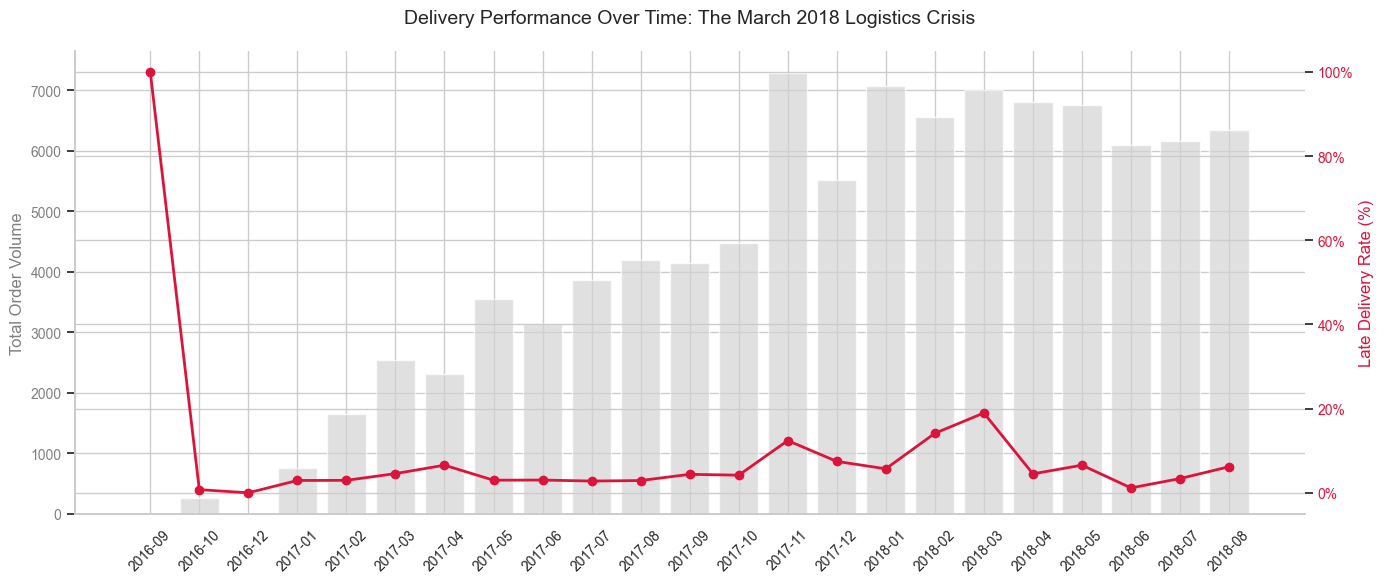

In [33]:
fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar chart for total order volume
ax1.bar(vol_by_month.index.astype(str), vol_by_month.values, color='lightgray', alpha=0.7, label='Total Orders')
ax1.set_ylabel('Total Order Volume', color='gray')
ax1.tick_params(axis='y', labelcolor='gray')
ax1.tick_params(axis='x', rotation=45)

# Secondary axis for late percentage
ax2 = ax1.twinx()
ax2.plot(late_by_month.index.astype(str), late_by_month.values, color='crimson', marker='o', linewidth=2, label='% Late')
ax2.set_ylabel('Late Delivery Rate (%)', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')
ax2.yaxis.set_major_formatter(ticker.PercentFormatter())

plt.title('Delivery Performance Over Time: The March 2018 Logistics Crisis', pad=20)
fig.tight_layout()
plt.show()

### Freight Economics (Distance vs. Cost)

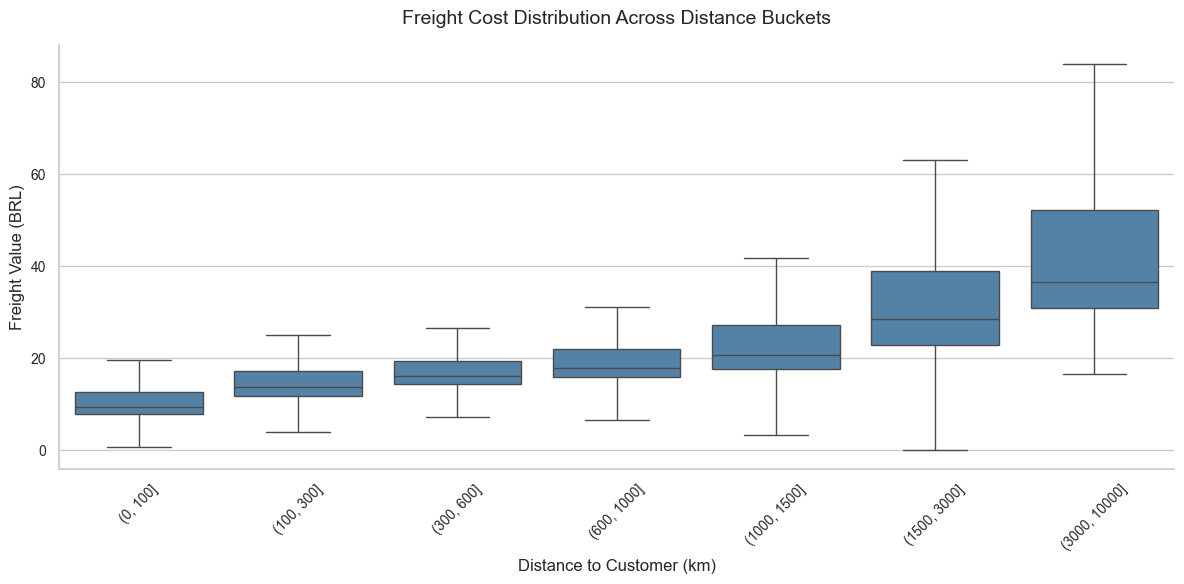

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))

# Using the valid DataFrame you created for freight vs distance
sns.boxplot(
    data=valid, 
    x='distance_bucket', 
    y='freight_value', 
    color="steelblue",
    showfliers=False # Hiding massive outliers to show the median trend clearly
)

plt.title('Freight Cost Distribution Across Distance Buckets', pad=15)
plt.xlabel('Distance to Customer (km)')
plt.ylabel('Freight Value (BRL)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### The Cost of Lateness (Customer Experience)

C:\Users\deema\AppData\Local\Temp\ipykernel_31608\1656086494.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\deema\AppData\Local\Temp\ipykernel_31608\1656086494.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['On-Time', 'Late'])


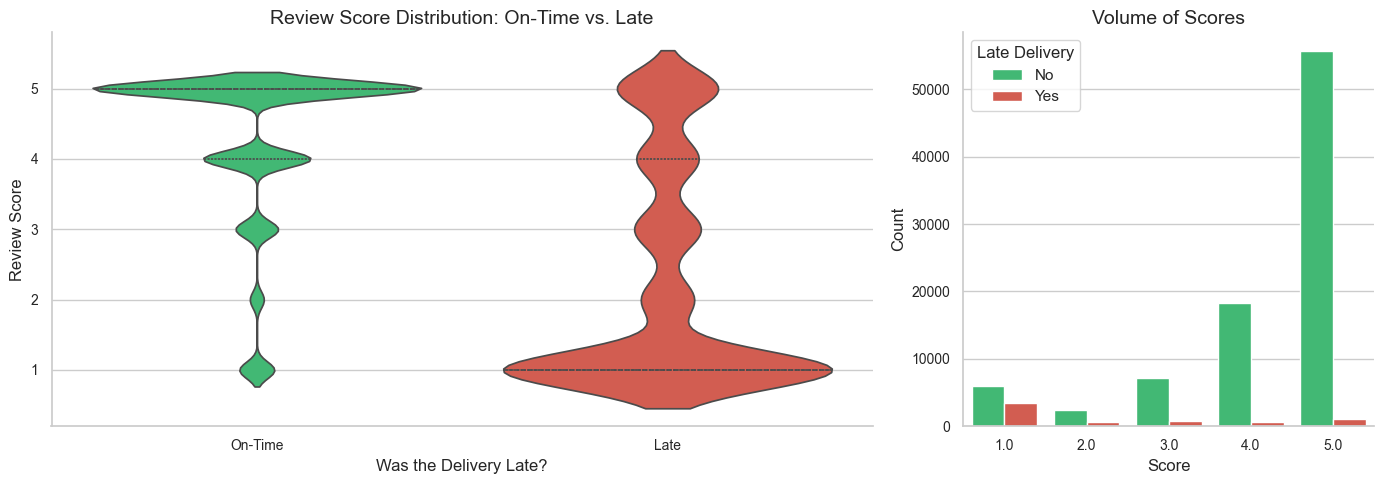

In [35]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})

# Violin plot showing the distribution shift
sns.violinplot(
    data=delivered_valid, 
    x='is_late', 
    y='review_score', 
    palette=['#2ecc71', '#e74c3c'], 
    inner='quartile',
    ax=ax1
)
ax1.set_title('Review Score Distribution: On-Time vs. Late')
ax1.set_xlabel('Was the Delivery Late?')
ax1.set_ylabel('Review Score')
ax1.set_xticklabels(['On-Time', 'Late'])

# Count plot showing the raw volume of 1-star vs 5-star reviews
sns.countplot(
    data=delivered_valid, 
    x='review_score', 
    hue='is_late', 
    palette=['#2ecc71', '#e74c3c'],
    ax=ax2
)
ax2.set_title('Volume of Scores')
ax2.set_xlabel('Score')
ax2.set_ylabel('Count')
ax2.legend(title='Late Delivery', labels=['No', 'Yes'])

plt.tight_layout()
plt.show()

### Installment Culture (Payments)

C:\Users\deema\AppData\Local\Temp\ipykernel_31608\604257935.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


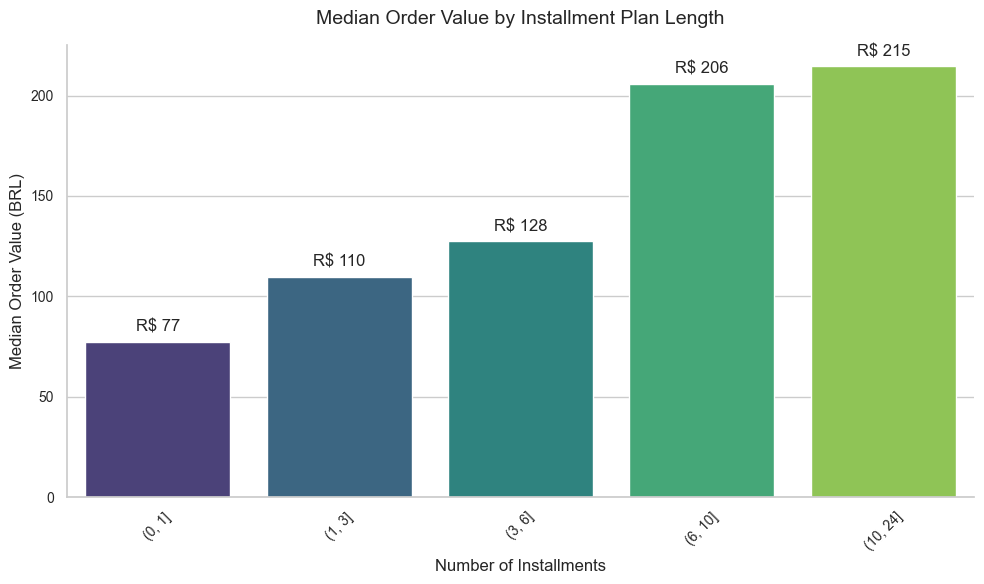

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))

# Calculate median order value per installment bucket
installment_stats = non_voucher.groupby(installment_bucket, observed=True)['payment_value'].median().reset_index()

sns.barplot(
    data=installment_stats, 
    x='payment_installments', 
    y='payment_value',
    palette="viridis"
)

plt.title('Median Order Value by Installment Plan Length', pad=15)
plt.xlabel('Number of Installments')
plt.ylabel('Median Order Value (BRL)')
plt.xticks(rotation=45)

# Annotate the bars with the exact median values
for p in ax.patches:
    ax.annotate(f'R$ {p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', 
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# finalizing DDL

In [37]:
# Does any customer_unique_id have more than one distinct customer_zip_code_prefix
dupe_check = customers.groupby("customer_unique_id")["customer_zip_code_prefix"].nunique()
print(dupe_check.value_counts())

customer_zip_code_prefix
1    95846
2      246
3        4
Name: count, dtype: int64


In [38]:
# Is seller_id already unique in the raw sellers file?
print(len(sellers), sellers["seller_id"].nunique())

3095 3095


In [39]:
# Date range to size dim_date — needs to cover purchase dates and estimated delivery dates (which extend later)
print(orders["order_purchase_timestamp"].min(), orders["order_purchase_timestamp"].max())
print(orders["order_estimated_delivery_date"].min(), orders["order_estimated_delivery_date"].max())

2016-09-04 21:15:19 2018-10-17 17:30:18
2016-09-30 00:00:00 2018-11-12 00:00:00


In [40]:
raw_reviews = pd.read_csv("../dataset/raw/olist_order_reviews_dataset.csv")
review_counts = raw_reviews.groupby("order_id").size()
print(review_counts.value_counts())
print(f"{(review_counts > 1).sum()} of {review_counts.shape[0]} orders have multiple raw review rows")

1    98126
2      543
3        4
Name: count, dtype: int64
547 of 98673 orders have multiple raw review rows


In [41]:
multi_review_orders = review_counts[review_counts > 1]

print(
    raw_reviews[
        raw_reviews["order_id"].isin(multi_review_orders.index)
    ].sort_values("order_id").head(20)
)

                              review_id                          order_id  \
22423  2a74b0559eb58fc1ff842ecc999594cb  0035246a40f520710769010f752e7507   
25612  89a02c45c340aeeb1354a24e7d4b2c1e  0035246a40f520710769010f752e7507   
22779  ab30810c29da5da8045216f0f62652a2  013056cfe49763c6f66bda03396c5ee3   
68633  73413b847f63e02bc752b364f6d05ee9  013056cfe49763c6f66bda03396c5ee3   
854    830636803620cdf8b6ffaf1b2f6e92b2  0176a6846bcb3b0d3aa3116a9a768597   
83224  d8e8c42271c8fb67b9dad95d98c8ff80  0176a6846bcb3b0d3aa3116a9a768597   
17582  017f0e1ea6386de662cbeba299c59ad1  02355020fd0a40a0d56df9f6ff060413   
89888  0c8e7347f1cdd2aede37371543e3d163  02355020fd0a40a0d56df9f6ff060413   
37911  04d945e95c788a3aa1ffbee42105637b  029863af4b968de1e5d6a82782e662f5   
55137  61fe4e7d1ae801bbe169eb67b86c6eda  029863af4b968de1e5d6a82782e662f5   
17847  2eab0b2e6f5bded4d9b0b2afcfdf4534  02e0b68852217f5715fb9cc885829454   
35812  fa493ead9b093fb0fa6f7d4905b0ef3b  02e0b68852217f5715fb9cc885829454   

In [42]:
from pathlib import Path

PROCESSED_DIR = Path("../dataset/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [43]:
order_master_export = order_master.drop(columns=["review_score", "review_creation_date", "review_answer_timestamp"])
order_master_export.to_parquet(PROCESSED_DIR / "order_master.parquet", index=False)

In [44]:
review_id_counts = raw_reviews.groupby("review_id").size()

print(review_id_counts.value_counts())

duplicate_review_ids = review_id_counts[review_id_counts > 1]

print(
    f"Duplicate review_id values: {len(duplicate_review_ids)}"
)

print(
    f"Rows involved in duplicated review_ids: "
    f"{duplicate_review_ids.sum()}"
)

1    97621
2      764
3       25
Name: count, dtype: int64
Duplicate review_id values: 789
Rows involved in duplicated review_ids: 1603


In [45]:
duplicate_ids = duplicate_review_ids.index

duplicate_reviews = (
    raw_reviews[
        raw_reviews["review_id"].isin(duplicate_ids)
    ]
    .sort_values(["review_id", "order_id"])
)

print(
    duplicate_reviews[
        [
            "review_id",
            "order_id",
            "review_score",
            "review_comment_title",
            "review_comment_message",
            "review_creation_date",
            "review_answer_timestamp"
        ]
    ].head(50)
)

                              review_id                          order_id  \
29841  00130cbe1f9d422698c812ed8ded1919  04a28263e085d399c97ae49e0b477efa   
46678  00130cbe1f9d422698c812ed8ded1919  dfcdfc43867d1c1381bfaf62d6b9c195   
63193  0115633a9c298b6a98bcbe4eee75345f  0c9850b2c179c1ef60d2855e2751d1fa   
90677  0115633a9c298b6a98bcbe4eee75345f  78a4201f58af3463bdab842eea4bc801   
57280  0174caf0ee5964646040cd94e15ac95e  74db91e33b4e1fd865356c89a61abf1f   
92876  0174caf0ee5964646040cd94e15ac95e  f93a732712407c02dce5dd5088d0f47b   
54832  017808d29fd1f942d97e50184dfb4c13  8daaa9e99d60fbba579cc1c3e3bfae01   
99167  017808d29fd1f942d97e50184dfb4c13  b1461c8882153b5fe68307c46a506e39   
96080  0254bd905dc677a6078990aad3331a36  331b367bdd766f3d1cf518777317b5d9   
20621  0254bd905dc677a6078990aad3331a36  5bf226cf882c5bf4247f89a97c86f273   
89712  0288d42bef3dfe36930740c9588a570f  33d8795f04dd631f3480d7aaf90da3dc   
94851  0288d42bef3dfe36930740c9588a570f  f889a5a0b44adc29c5465b99395ac3c1   

In [46]:
duplicate_review_ids = review_id_counts[review_id_counts > 1].index

dup_reviews = (
    raw_reviews[
        raw_reviews["review_id"].isin(duplicate_review_ids)
    ]
    .copy()
)

print("Duplicate review_id values:", dup_reviews["review_id"].nunique())
print("Rows involved:", len(dup_reviews))

# How many duplicated review_ids occur across multiple orders?
orders_per_review = dup_reviews.groupby("review_id")["order_id"].nunique()

print("\nOrders per duplicated review_id:")
print(orders_per_review.value_counts())

print(
    "\nReview IDs associated with >1 order:",
    (orders_per_review > 1).sum()
)

# Check whether duplicated review_id rows are otherwise identical
check_cols = [
    "review_id",
    "order_id",
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp"
]

sample = (
    dup_reviews[check_cols]
    .sort_values(["review_id", "order_id"])
)

print("\nSample duplicated review_ids:")
print(sample.head(30).to_string(index=False))

Duplicate review_id values: 789
Rows involved: 1603

Orders per duplicated review_id:
order_id
2    764
3     25
Name: count, dtype: int64

Review IDs associated with >1 order: 789

Sample duplicated review_ids:
                       review_id                         order_id  review_score review_comment_title                                                                                                                                                                                   review_comment_message review_creation_date review_answer_timestamp
00130cbe1f9d422698c812ed8ded1919 04a28263e085d399c97ae49e0b477efa             1                  NaN               O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.   2018-03-07 00:00:00     2018-03-20 18:08:23
00130cbe1f9d422698c812ed8ded1919 dfcdfc43867d1c1381bfaf62d6b9c195             1               

In [47]:
# Get review_ids that appear against multiple orders
duplicate_review_ids = (
    raw_reviews.groupby("review_id")
    .filter(lambda g: g["order_id"].nunique() > 1)
    ["review_id"]
    .unique()
)

dup_reviews = raw_reviews[
    raw_reviews["review_id"].isin(duplicate_review_ids)
].copy()

# Attach customer information through orders
review_customer = dup_reviews.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

# Attach the real customer identity
review_customer = review_customer.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Attach product information through order_items
review_customer_product = review_customer.merge(
    order_items[["order_id", "product_id"]],
    on="order_id",
    how="left"
)

# Summarise each duplicated review_id
review_id_behavior = (
    review_customer_product
    .groupby("review_id")
    .agg(
        n_rows=("review_id", "size"),
        n_orders=("order_id", "nunique"),
        n_customers=("customer_unique_id", "nunique"),
        n_products=("product_id", "nunique")
    )
    .reset_index()
)

print(review_id_behavior[[
    "n_customers",
    "n_products"
]].value_counts().head(20))

print("\nSummary:")
print(review_id_behavior[[
    "n_orders",
    "n_customers",
    "n_products"
]].describe())

n_customers  n_products
1            2             591
             1              94
             3              75
             4              18
             0               5
             5               4
             7               2
Name: count, dtype: int64

Summary:
         n_orders  n_customers  n_products
count  789.000000        789.0  789.000000
mean     2.031686          1.0    2.036755
std      0.175273          0.0    0.662573
min      2.000000          1.0    0.000000
25%      2.000000          1.0    2.000000
50%      2.000000          1.0    2.000000
75%      2.000000          1.0    2.000000
max      3.000000          1.0    7.000000


In [48]:
# Show examples where the same review_id is associated
# with multiple customers or multiple products

interesting = review_id_behavior[
    (review_id_behavior["n_customers"] > 1) |
    (review_id_behavior["n_products"] > 1)
]

print(
    f"Review IDs involving >1 customer or >1 product: "
    f"{len(interesting)}"
)

example_ids = interesting["review_id"].head(10)

print(
    review_customer_product[
        review_customer_product["review_id"].isin(example_ids)
    ][[
        "review_id",
        "order_id",
        "customer_unique_id",
        "product_id",
        "review_score",
        "review_comment_message",
        "review_creation_date"
    ]]
    .sort_values(["review_id", "order_id"])
    .to_string(index=False)
)

Review IDs involving >1 customer or >1 product: 690
                       review_id                         order_id               customer_unique_id                       product_id  review_score                                                                                                                                                                     review_comment_message review_creation_date
00130cbe1f9d422698c812ed8ded1919 04a28263e085d399c97ae49e0b477efa f30856ad31d3e74253a3f4ccef670648 3f14d740544f37ece8a9e7bc8349797e             1 O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funcionou. Além de ter chegado com atraso de mais de 15 dias do previsto. Preciso que seja trocado.   2018-03-07 00:00:00
00130cbe1f9d422698c812ed8ded1919 dfcdfc43867d1c1381bfaf62d6b9c195 f30856ad31d3e74253a3f4ccef670648 36f60d45225e60c7da4558b070ce4b60             1 O cartucho "original HP" 60XL não é reconhecido pela impressora, consequentemente não funciono

In [49]:
dup_ids = raw_reviews.groupby("review_id")["order_id"].nunique()
dup_ids = dup_ids[dup_ids > 1]
print(len(dup_ids))  # should be 789

789


### Parquet conversion

In [50]:
raw_reviews = dfs["order_reviews"].copy()
raw_reviews["review_creation_date"] = pd.to_datetime(raw_reviews["review_creation_date"])
raw_reviews["review_answer_timestamp"] = pd.to_datetime(raw_reviews["review_answer_timestamp"])

logistics_kw = ["entreg", "prazo", "atras", "não recebi", "nao recebi", "transportadora", "demora"]
refund_kw = ["reembolso", "estorno", "cancel", "devol"]

def has_kw(text, kws):
    if pd.isna(text):
        return False
    t = text.lower()
    return any(k in t for k in kws)

raw_reviews["has_logistics_keyword"] = raw_reviews["review_comment_message"].apply(lambda t: has_kw(t, logistics_kw))
raw_reviews["has_refund_keyword"] = raw_reviews["review_comment_message"].apply(lambda t: has_kw(t, refund_kw))

raw_reviews["response_days"] = (
    raw_reviews["review_answer_timestamp"] - raw_reviews["review_creation_date"]
).dt.days

# most-recent review per ORDER (order-level convenience flag)
raw_reviews["is_most_recent_review"] = (
    raw_reviews
    .sort_values(["order_id", "review_answer_timestamp", "review_id"])
    .groupby("order_id")
    .cumcount(ascending=False) == 0
)

# operationalizes today's finding directly in the fact table
review_id_counts = raw_reviews.groupby("review_id")["order_id"].transform("nunique")
raw_reviews["review_id_reused_across_orders"] = review_id_counts > 1

print(f"rows: {len(raw_reviews)}  |  unique order_id: {raw_reviews['order_id'].nunique()}  |  "
      f"unique review_id: {raw_reviews['review_id'].nunique()}  |  "
      f"reused review_id rows: {raw_reviews['review_id_reused_across_orders'].sum()}")

raw_reviews.to_parquet(PROCESSED_DIR / "reviews_full.parquet", index=False)

rows: 99224  |  unique order_id: 98673  |  unique review_id: 98410  |  reused review_id rows: 1603


In [51]:
print(order_master.shape)

(99441, 22)


In [52]:
# 1. customers.parquet
# Keep raw/order-grain customer rows.
# Type 1 customer_unique_id collapse happens during Week 2 ETL.
dfs["customers"].to_parquet(
    PROCESSED_DIR / "customers.parquet",
    index=False
)

# 2. sellers.parquet
dfs["sellers"].to_parquet(
    PROCESSED_DIR / "sellers.parquet",
    index=False
)

# 3. products_clean.parquet
# This is the category-patched products dataframe.
dfs["products"].to_parquet(
    PROCESSED_DIR / "products_clean.parquet",
    index=False
)

# 4. order_items.parquet
# Preserve raw order-item grain.
order_items_export = dfs["order_items"][
    [
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value"
    ]
]

order_items_export.to_parquet(
    PROCESSED_DIR / "order_items.parquet",
    index=False
)

# 5. dim_geo.parquet
# Final cleaned geolocation dimension.
dim_geo.to_parquet(
    PROCESSED_DIR / "dim_geo.parquet",
    index=False
)

# ================================================================
# VALIDATION
# ================================================================

print("\n=== WEEK 2 PARQUET ARTIFACTS ===")

checks = [
    ("order_master.parquet", order_master_export, "order_id"),
    ("reviews_full.parquet", raw_reviews, None),
    ("customers.parquet", dfs["customers"], "customer_id"),
    ("sellers.parquet", dfs["sellers"], "seller_id"),
    ("products_clean.parquet", dfs["products"], "product_id"),
    ("order_items.parquet", order_items_export, None),
    ("dim_geo.parquet", dim_geo, "geolocation_zip_code_prefix"),
]

for fname, df, key in checks:
    print(f"\n{fname}")
    print(f"  rows: {len(df):,}")

    if key:
        print(f"  {key}: {df[key].nunique():,} unique")

print("\n=== GEO CONFIDENCE ===")
print(dim_geo["confidence"].value_counts())

print("\n=== FILES PRESENT ===")
for f in sorted(PROCESSED_DIR.glob("*.parquet")):
    print(f"  {f.name}")


=== WEEK 2 PARQUET ARTIFACTS ===

order_master.parquet
  rows: 99,441
  order_id: 99,441 unique

reviews_full.parquet
  rows: 99,224

customers.parquet
  rows: 99,441
  customer_id: 99,441 unique

sellers.parquet
  rows: 3,095
  seller_id: 3,095 unique

products_clean.parquet
  rows: 32,951
  product_id: 32,951 unique

order_items.parquet
  rows: 112,650

dim_geo.parquet
  rows: 19,001
  geolocation_zip_code_prefix: 19,001 unique

=== GEO CONFIDENCE ===
confidence
High      11847
Medium     5148
Low        2006
Name: count, dtype: int64

=== FILES PRESENT ===
  customers.parquet
  dim_geo.parquet
  order_items.parquet
  order_master.parquet
  products_clean.parquet
  reviews_full.parquet
  sellers.parquet
